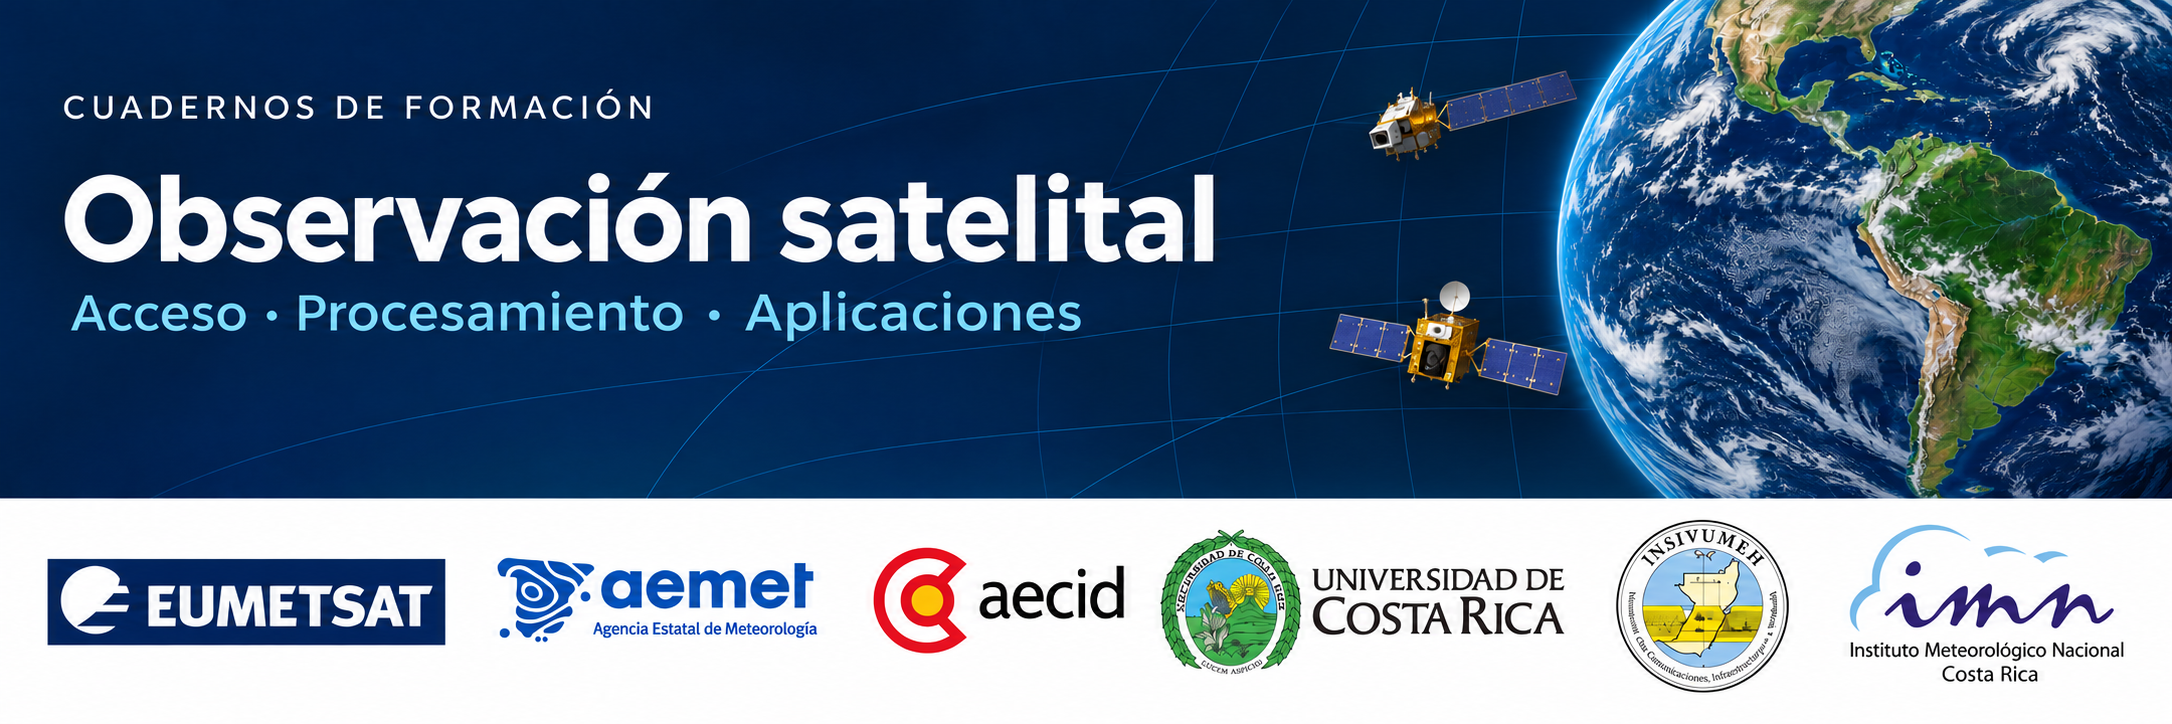

# Julia · Altimetría satelital con EUMDAC
### Nicaragua · 7–10 de octubre de 2022
**Taller de acceso y análisis de datos satelitales · Uruguay**  
Sentinel-3A/B · SRAL | Sentinel-6A · Poseidon-4  
Versión 1.2 · 19 de noviembre de 2026 · Material en español

**Pregunta guía:** ¿hay una pasada altimétrica suficientemente cercana, en espacio y tiempo,
para aportar evidencia sobre el nivel del mar y el oleaje durante Julia?

Julia tocó tierra cerca de Laguna de Perlas el **9 de octubre de 2022 a las 07:15 UTC**,
equivalentes a **01:15 en Nicaragua**. El punto de referencia aproximado es 12,4° N, 83,6° O.
Ese momento no se supone idéntico al máximo de marejada de cada localidad.

> **Qué produce este notebook:** inventario de productos, descargas NetCDF con EUMDAC,
> mapa de muestras realmente presentes, perfiles de anomalía del nivel del mar (SSHA)
> y altura significativa del oleaje (SWH), CSV y un paquete de resultados.
> **La SSHA del producto conserva sus correcciones. No es automáticamente la marejada ciclónica.**

**Requisitos:** Python 3.10 o posterior (64 bits recomendado), Internet y cuenta gratuita de
[EUMETSAT Data Store](https://data.eumetsat.int). Se utiliza **Consumer key + Consumer secret**;
no se solicita usuario ni contraseña. Compatible con Google Colab y Jupyter/Anaconda.

**Ruta de trabajo:** preparar → autenticar → buscar → seleccionar → descargar → inspeccionar → interpretar.
Ejecute las celdas en orden. La primera ejecución descarga hasta 12 archivos estándar;
las siguientes reutilizan archivos verificados. La instalación y la descarga de productos requieren Internet; el mapa lleva sus recursos incorporados.

## 1 · Preparar el entorno
La instalación se hace en el kernel activo. Si acaba de actualizar NumPy y aparece un error
de compatibilidad binaria, reinicie el kernel y vuelva a ejecutar desde esta sección.
No se instala Cartopy ni se exige una extensión de widgets.

In [3]:
%pip -q install "eumdac>=3.1.1,<4" "netCDF4>=1.6,<2" "numpy>=1.24,<3" "pandas>=2,<3" "matplotlib>=3.7,<4" "folium>=0.15,<1"

In [4]:
import os, sys, json, re, html, hashlib, warnings, zipfile
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass
import numpy as np
import pandas as pd
import netCDF4 as nc
import matplotlib.pyplot as plt
import folium
import eumdac
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 220,
                     "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"Python {sys.version.split()[0]} · EUMDAC {eumdac.__version__}")

Python 3.13.18 · EUMDAC 3.1.1


## 2 · Definir el caso
El intervalo es **[inicio, fin)**: el fin no se incluye al recortar las muestras.
La región predeterminada incluye la costa caribeña de Nicaragua y aguas al este.
Para revisar antecedentes, amplíe el inicio; para buscar el instante del impacto, reduzca la ventana.

**STD** es la opción recomendada: conserva más variables y banderas de calidad.
**RED** es más pequeño, pero en los archivos reales de Sentinel-3 probados omite las banderas específicas
de SSHA y SWH. STD incorpora también 20 Hz, pero este notebook analiza exclusivamente **1 Hz y banda Ku**
para comparar las misiones de forma consistente. El muestreo no equivale al tamaño de la huella radar.

In [5]:
INICIO_UTC = "2022-10-07T00:00:00Z"  #@param {type:"string"}
FIN_UTC = "2022-10-11T00:00:00Z"  #@param {type:"string"}
IMPACTO_UTC = "2022-10-09T07:15:00Z"
OESTE, SUR, ESTE, NORTE = -84.5, 10.5, -80.0, 15.0
BBOX = (OESTE, SUR, ESTE, NORTE)
PUNTO_IMPACTO = (-83.6, 12.4)  # longitud, latitud; referencia aproximada

COLECCIONES = {
    "EO:EUM:DAT:1079": "Sentinel-3A/B · SRAL L2 · BC006/G62 reprocesado",
    "EO:EUM:DAT:1072": "Sentinel-6A · Poseidon-4 L2 HR · G01 reprocesado",
}
VARIANTE = "STD"  # STD recomendado por sus banderas; RED es más ligero. No se usa ENH.
MAX_PRODUCTOS_POR_COLECCION = 80
MAX_DESCARGAS = 12
MAX_MB_POR_ARCHIVO = 250
INDICES_ELEGIDOS = []  # [] reparte el cupo entre satélites; ejemplo manual: [0, 2, 5]
SOLO_BANDERA_DE_VARIABLE = True  # False permite gráficos exploratorios con QC parcial, rotulados.
SALIDA = Path("Julia_Altimetria_resultados")
SALIDA.mkdir(parents=True, exist_ok=True)
print("Región (O,S,E,N):", BBOX)
print("Ventana UTC:", INICIO_UTC, "→", FIN_UTC)

Región (O,S,E,N): (-84.5, 10.5, -80.0, 15.0)
Ventana UTC: 2022-10-07T00:00:00Z → 2022-10-11T00:00:00Z


### Colecciones seleccionadas y alternativas
Las dos colecciones activas cubren octubre de 2022 según el catálogo consultado el 19/11/2026.
No se consulta un archivo de tiempo casi real para recuperar un evento antiguo.

| Colección | Contenido | Período del catálogo consultado |
|---|---|---|
| `EO:EUM:DAT:1079` | Sentinel-3A/B, SRAL L2, BC006/G62 | 01/03/2016–31/01/2026 |
| `EO:EUM:DAT:1072` | Sentinel-6A, Poseidon-4 L2 HR, G01 | 17/12/2020–20/04/2025 |
| `EO:EUM:DAT:1074` | Sentinel-6A, Poseidon-4 L2 LR, G01; alternativa | 17/12/2020–20/04/2025 |

**HR y LR son modos de procesamiento del altímetro**, no la elección de archivo RED o STD.
No active simultáneamente HR y LR para contar cobertura: pueden corresponder a la misma pasada.
Las colecciones y sus períodos pueden cambiar; ante una retirada, revise la sección 12.
Este notebook no descarga ASCAT, porque ASCAT es un dispersómetro de viento y no un altímetro.

## 3 · Autenticación: solo key y secret
Obtenga sus claves en [API key de Data Store](https://api.eumetsat.int/api-key/).
Acepte la licencia del producto en el portal si se solicita.

Puede crear secretos de Colab llamados **EUMETSAT_KEY** y **EUMETSAT_SECRET** y permitir que el notebook
los utilice. También se aceptan variables de entorno con esos nombres, o EUMDAC_KEY/EUMDAC_SECRET.
Si no existen, se solicita entrada oculta. Las claves no se guardan en los resultados ni en celdas de texto.

In [6]:
def obtener_secreto(nombres):
    for nombre in nombres:
        valor = os.environ.get(nombre, "").strip()
        if valor:
            return valor
    try:
        from google.colab import userdata
        for nombre in nombres:
            try:
                valor = userdata.get(nombre)
                if valor:
                    return valor.strip()
            except Exception:
                pass
    except ImportError:
        pass
    return getpass(f"{nombres[0]} (entrada oculta): ").strip()

def conectar_eumetsat():
    clave = obtener_secreto(["EUMETSAT_KEY", "EUMDAC_KEY"])
    secreto = obtener_secreto(["EUMETSAT_SECRET", "EUMDAC_SECRET"])
    if not clave or not secreto:
        raise RuntimeError("Faltan Consumer key o Consumer secret.")
    try:
        token = eumdac.AccessToken((clave, secreto))
        _ = str(token)  # valida el token sin mostrarlo
        return eumdac.DataStore(token)
    except Exception:
        raise RuntimeError("No se pudo autenticar. Revisar conexión y Consumer key/secret de Data Store; no son usuario/contraseña.") from None

datastore = conectar_eumetsat()
print("Autenticación completada. No se muestran ni exportan las credenciales.")

EUMETSAT_KEY (entrada oculta): ··········
EUMETSAT_SECRET (entrada oculta): ··········
Autenticación completada. No se muestran ni exportan las credenciales.


## 4 · Funciones de acceso y lectura
Ejecute estas tres celdas una vez. Puede mantenerlas contraídas.
La descarga usa **`product.open(entry=...)`** para obtener un solo NetCDF dentro del producto.
Se reconocen tanto `reduced_measurement.nc` como los nombres nuevos de Sentinel-3 G62.
Los archivos incompletos no se consideran descargas terminadas.

In [7]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from itertools import islice
import hashlib
import json
import re
import html
import warnings
import numpy as np
import pandas as pd
import netCDF4 as nc


def mensaje_error(exc):
    """Diagnóstico sin imprimir solicitudes, cabeceras ni credenciales."""
    estado = getattr(getattr(exc, 'response', None), 'status_code', None)
    if estado in (401, 403):
        return f'HTTP {estado}: revisar Consumer key/secret y aceptación de la licencia en Data Store.'
    if estado == 429:
        return 'HTTP 429: límite del servicio; reintentar más tarde con menos productos.'
    if estado:
        return f'HTTP {estado}: revisar estado del servicio y colección.'
    return f'{type(exc).__name__}: revisar conexión, colección y fechas; no se muestran datos de autenticación.'


def buscar_productos(datastore, colecciones, inicio, fin, bbox, impacto, limite=80):
    """Una fila por producto; el bbox del catálogo NO garantiza muestras locales."""
    oeste, sur, este, norte = bbox
    if not (-180 <= oeste < este <= 180 and -90 <= sur < norte <= 90):
        raise ValueError('BBOX debe ser (oeste, sur, este, norte), sin cruzar el antimeridiano.')
    inicio, fin, impacto = [pd.Timestamp(x) for x in (inicio, fin, impacto)]
    if any(x.tzinfo is None for x in (inicio, fin, impacto)) or inicio >= fin:
        raise ValueError('Usar fechas UTC con Z; inicio debe ser anterior al fin.')
    filas, estados, objetos = [], [], {}
    for codigo, descripcion in colecciones.items():
        try:
            coleccion = datastore.get_collection(codigo)
            resultados = coleccion.search(
                dtstart=inicio.to_pydatetime(), dtend=fin.to_pydatetime(),
                bbox=','.join(map(str, bbox)))
            total = resultados.total_results
            productos = list(islice(resultados, limite))
            estados.append({'coleccion': codigo, 'nombre': descripcion,
                            'coincidencias_catalogo': total, 'revisados': len(productos),
                            'estado': 'TRUNCADO: reducir ventana o aumentar límite' if total > limite else 'OK'})
            for producto in productos:
                identificador = str(producto)
                t0, t1 = pd.Timestamp(producto.sensing_start), pd.Timestamp(producto.sensing_end)
                t0 = t0.tz_localize('UTC') if t0.tzinfo is None else t0.tz_convert('UTC')
                t1 = t1.tz_localize('UTC') if t1.tzinfo is None else t1.tz_convert('UTC')
                delta = max((t0-impacto).total_seconds(), (impacto-t1).total_seconds(), 0)/3600
                satelite = next((s for s in ('S3A', 'S3B', 'S6A', 'S6B') if identificador.startswith(s)), 'otro')
                clave = (codigo, identificador)
                objetos[clave] = producto
                filas.append({'coleccion': codigo, 'satelite': satelite, 'producto': identificador,
                              'inicio_UTC': t0, 'fin_UTC': t1, 'distancia_temporal_catalogo_h': delta})
        except Exception as exc:
            estados.append({'coleccion': codigo, 'nombre': descripcion, 'estado': mensaje_error(exc)})
    tabla = pd.DataFrame(filas)
    if len(tabla):
        tabla = tabla.drop_duplicates(['coleccion', 'producto']).sort_values(
            ['distancia_temporal_catalogo_h', 'inicio_UTC']).reset_index(drop=True)
        tabla.index.name = 'indice'
    return tabla, pd.DataFrame(estados), objetos


def seleccionar_productos(tabla, maximo=12, indices=None):
    """Reparte el cupo entre satélites; no selecciona siempre la primera misión."""
    if tabla.empty:
        return tabla.copy()
    if indices:
        if len(set(indices)) != len(indices) or any(i not in tabla.index for i in indices):
            raise ValueError('Hay índices repetidos o ausentes en el inventario.')
        if len(indices) > maximo:
            raise ValueError('La selección supera MAX_DESCARGAS. Cambiar el límite de forma explícita.')
        return tabla.loc[indices].copy()
    grupos = [list(g.index) for _, g in tabla.groupby('satelite', sort=False)]
    elegidos = []
    while any(grupos) and len(elegidos) < maximo:
        for grupo in grupos:
            if grupo and len(elegidos) < maximo:
                elegidos.append(grupo.pop(0))
    return tabla.loc[elegidos].copy()


def elegir_entrada(entries, variante='RED'):
    """Reconoce nombres antiguos y G62; evita ENH y ficheros auxiliares."""
    if variante not in ('RED', 'STD'):
        raise ValueError('VARIANTE debe ser RED o STD.')
    archivos = [str(x) for x in entries if str(x).lower().endswith('.nc')]
    def tipo(nombre):
        n = PurePosixPath(nombre).name.lower()
        if 'reduced' in n or re.search(r'(^|[_-])red([_.-]|$)', n):
            return 'RED'
        if 'standard' in n or re.search(r'(^|[_-])std([_.-]|$)', n):
            return 'STD'
        return None
    for categoria in ([variante, 'STD'] if variante == 'RED' else ['STD']):
        candidatos = [x for x in archivos if tipo(x) == categoria]
        if len(candidatos) == 1:
            return candidatos[0], categoria
        if len(candidatos) > 1:
            raise ValueError('Más de un NetCDF de la variante solicitada; revisar product.entries.')
    raise ValueError('No se identificó RED/STD. Revisar product.entries; no se descarga el ZIP completo.')


def validar_netcdf(ruta):
    with nc.Dataset(str(ruta)) as ds:
        if not ds.variables and not ds.groups:
            raise ValueError('NetCDF sin variables ni grupos.')


def descargar_entrada(producto, coleccion, carpeta, variante='RED', max_mb=250):
    """Caché con identidad y SHA256; descarga atómica y límite por fichero."""
    entrada, real = elegir_entrada(producto.entries, variante)
    identidad = {'coleccion': coleccion, 'producto': str(producto), 'entrada': entrada}
    codigo = hashlib.sha256(json.dumps(identidad, sort_keys=True).encode()).hexdigest()[:20]
    destino = Path(carpeta) / f'{codigo}_{real}.nc'
    destino.parent.mkdir(parents=True, exist_ok=True)
    ficha = destino.with_suffix('.json')
    def sha256(ruta):
        h = hashlib.sha256()
        with open(ruta, 'rb') as f:
            for bloque in iter(lambda: f.read(1024*1024), b''):
                h.update(bloque)
        return h.hexdigest()
    if destino.exists() and ficha.exists():
        try:
            previo = json.loads(ficha.read_text(encoding='utf-8'))
            if (all(previo.get(k) == v for k, v in identidad.items()) and
                    previo.get('sha256') == sha256(destino)):
                validar_netcdf(destino)
                return destino, {**previo, 'cache': True}
        except (OSError, ValueError):
            pass
    temporal = destino.with_suffix('.part')
    try:
        tamano = 0
        with producto.open(entry=entrada) as origen, open(temporal, 'wb') as salida:
            while True:
                bloque = origen.read(1024*1024)
                if not bloque:
                    break
                tamano += len(bloque)
                if tamano > max_mb*1024*1024:
                    raise ValueError(f'El archivo supera el límite de {max_mb} MiB.')
                salida.write(bloque)
        validar_netcdf(temporal)
        registro = {**identidad, 'variante': real, 'bytes': tamano,
                    'sha256': sha256(temporal), 'descarga_UTC': datetime.now(timezone.utc).isoformat()}
        temporal.replace(destino)
        ficha.write_text(json.dumps(registro, indent=2, ensure_ascii=False), encoding='utf-8')
        return destino, {**registro, 'cache': False}
    finally:
        if temporal.exists():
            temporal.unlink()

In [8]:
def variables_netcdf(grupo, prefijo=''):
    salida = {f'{prefijo}{k}': v for k, v in grupo.variables.items()}
    for nombre, subgrupo in grupo.groups.items():
        salida.update(variables_netcdf(subgrupo, f'{prefijo}{nombre}/'))
    return salida


def inventario_netcdf(ruta):
    with nc.Dataset(str(ruta)) as ds:
        return pd.DataFrame([{'ruta': p, 'dimensiones': str(v.dimensions), 'forma': str(v.shape),
            'unidades': getattr(v, 'units', ''), 'descripcion': getattr(v, 'long_name', ''),
            'flag_meanings': getattr(v, 'flag_meanings', '')}
            for p, v in variables_netcdf(ds).items()])


def vector(v, n=None):
    a = np.ma.asarray(v[:], dtype=float).filled(np.nan)
    if a.ndim != 1 or (n is not None and len(a) != n):
        raise ValueError(f'{v.name}: se esperaba un vector de {n} muestras a 1 Hz; forma {a.shape}.')
    return a


def metros(v, n):
    unidad = str(getattr(v, 'units', '')).lower().strip()
    escalas = {'m': 1., 'meter': 1., 'meters': 1., 'metre': 1., 'metres': 1., 'cm': .01, 'mm': .001}
    if unidad not in escalas:
        raise ValueError(f'Unidades de altura no reconocidas en {v.name}: {unidad!r}.')
    return vector(v, n)*escalas[unidad]


def bandera_buena(v, n):
    """Respeta flag_values/meanings; solo usa cero para nombres documentados."""
    valores = vector(v, n)
    sentidos = str(getattr(v, 'flag_meanings', '')).lower().split()
    codigos = np.atleast_1d(getattr(v, 'flag_values', []))
    buenos = [codigos[i] for i, s in enumerate(sentidos)
              if s in ('good', 'valid', 'good_data', 'valid_data', 'good_quality') and i < len(codigos)]
    if buenos and not hasattr(v, 'flag_masks'):
        return np.isfinite(valores) & np.isin(valores, buenos)
    if not sentidos and not hasattr(v, 'flag_masks') and (
        v.name.startswith('quality_') or v.name in ('ssha_qual', 'swh_ocean_qual', 'range_ocean_qual')
        or v.name.startswith(('ssha_qual_01', 'swh_ocean_qual_01'))):
        return np.isfinite(valores) & (valores == 0)
    raise ValueError(f'No se puede interpretar de forma segura la bandera {v.name}. Revisar sus atributos.')

In [9]:
def leer_altimetria(ruta, bbox, inicio, fin, impacto, referencia=(-83.6, 12.4)):
    """Lectura 1 Hz: S3 plano y S6 con grupos; jamás mezcla frecuencias ni banda C/Ku."""
    with nc.Dataset(str(ruta)) as ds:
        variables = variables_netcdf(ds)
        es_s6 = 'data_01/latitude' in variables
        if es_s6:
            esquema = {'latitud': ['data_01/latitude'], 'longitud': ['data_01/longitude'],
                'tiempo': ['data_01/time'], 'ssha_m': ['data_01/ku/ssha'],
                'swh_m': ['data_01/ku/swh_ocean'],
                'qc_ssha': ['data_01/ku/quality_ssha', 'data_01/ku/ssha_qual'],
                'qc_swh': ['data_01/ku/quality_swh_ocean', 'data_01/ku/swh_ocean_qual'],
                'qc_rango': ['data_01/ku/range_ocean_qual'],
                'superficie': ['data_01/surface_classification_flag', 'data_01/surface_type'],
                'distancia_costa': ['data_01/distance_to_coast']}
            correcciones = ['data_01/dac', 'data_01/inv_bar_cor', 'data_01/ocean_tide_sol1',
                            'data_01/ocean_tide_sol2', 'data_01/pole_tide', 'data_01/solid_earth_tide']
        else:
            esquema = {'latitud': ['lat_01'], 'longitud': ['lon_01'], 'tiempo': ['time_01'],
                'ssha_m': ['ssha_01_ku'], 'swh_m': ['swh_ocean_01_ku'],
                'qc_ssha': ['quality_ssha_01_ku', 'ssha_qual_01_ku'],
                'qc_swh': ['quality_swh_ocean_01_ku', 'swh_ocean_qual_01_ku'],
                'qc_rango': ['range_ocean_qual_01_ku'],
                'superficie': ['surf_type_01'], 'distancia_costa': ['dist_coast_01', 'distance_to_coast_01']}
            correcciones = ['inv_bar_cor_01', 'hf_fluct_cor_01', 'dac_01', 'ocean_tide_sol1_01',
                            'ocean_tide_sol2_01', 'pole_tide_01', 'solid_earth_tide_01']
        usados = {k: next((p for p in opciones if p in variables), None) for k, opciones in esquema.items()}
        for esencial in ('latitud', 'longitud', 'tiempo'):
            if usados[esencial] is None:
                raise ValueError(f'Falta {esencial} a 1 Hz; inspeccionar inventario_netcdf().')
        lat = vector(variables[usados['latitud']]); n = len(lat)
        lon = (vector(variables[usados['longitud']], n)+180)%360-180
        tv = variables[usados['tiempo']]
        numerico = vector(tv, n)
        fechas = np.full(n, np.datetime64('NaT'), dtype='datetime64[ns]')
        validos_t = np.isfinite(numerico)
        if validos_t.any():
            dec = nc.num2date(numerico[validos_t], units=tv.units,
                calendar=getattr(tv, 'calendar', 'standard'), only_use_cftime_datetimes=False)
            fechas[validos_t] = np.asarray(dec, dtype='datetime64[ns]')
        tiempo = pd.to_datetime(fechas, utc=True)
        mar = np.ones(n, dtype=bool); estado_superficie = 'sin máscara de superficie'
        if usados['superficie']:
            v = variables[usados['superficie']]
            significados = str(getattr(v, 'flag_meanings', '')).lower().split()
            valores = np.atleast_1d(getattr(v, 'flag_values', []))
            codigos = [valores[i] for i, s in enumerate(significados)
                       if s in ('ocean', 'open_ocean', 'sea', 'open_sea', 'ocean_or_semi_enclosed_sea') and i < len(valores)]
            if not codigos and v.name == 'surf_type_01':
                codigos = [0]  # SRAL PFS: open ocean.
            if codigos:
                mar = np.isin(vector(v, n), codigos)
                estado_superficie = 'océano según máscara del producto'
        datos = {'tiempo_UTC': tiempo, 'latitud': lat, 'longitud': lon}
        for campo, llave_qc in [('ssha_m', 'qc_ssha'), ('swh_m', 'qc_swh')]:
            a = metros(variables[usados[campo]], n) if usados[campo] else np.full(n, np.nan)
            datos[campo+'_original'] = a.copy()
            calidad = np.ones(n, bool)
            categoria = 'sin bandera de variable; exploratorio'
            qpath = usados[llave_qc]
            if qpath:
                calidad = bandera_buena(variables[qpath], n)
                categoria = 'bandera de variable aplicada'
            elif campo == 'ssha_m' and usados['qc_rango']:
                calidad = bandera_buena(variables[usados['qc_rango']], n)
                categoria = 'solo bandera de rango; QC parcial'
            if campo == 'swh_m':
                calidad &= a >= 0
            datos[campo] = np.where(mar & calidad & np.isfinite(a), a, np.nan)
            datos[campo+'_estado_qc'] = categoria
        for p in correcciones:
            if p in variables:
                try:
                    datos['correccion__'+p.replace('/', '__')] = metros(variables[p], n)
                except ValueError:
                    warnings.warn(f'No se exportó {p}: comprobar unidades o dimensiones.')
        if usados['distancia_costa']:
            v = variables[usados['distancia_costa']]
            u = str(getattr(v, 'units', '')).lower()
            if u in ('m', 'km'):
                datos['distancia_costa_km'] = vector(v, n)*(0.001 if u == 'm' else 1.)
        df = pd.DataFrame(datos)
        w, s, e, nn = bbox
        dentro = (df.longitud.between(w,e) & df.latitud.between(s,nn) &
                  (df.tiempo_UTC >= pd.Timestamp(inicio)) & (df.tiempo_UTC < pd.Timestamp(fin)))
        df = df.loc[dentro].copy()
        df['horas_desde_impacto'] = (df.tiempo_UTC-pd.Timestamp(impacto)).dt.total_seconds()/3600
        x0, y0 = np.radians(referencia)
        x, y = np.radians(df.longitud), np.radians(df.latitud)
        h = np.sin((y-y0)/2)**2 + np.cos(y)*np.cos(y0)*np.sin((x-x0)/2)**2
        df['distancia_punto_impacto_km'] = 6371.0088*2*np.arcsin(np.sqrt(np.clip(h,0,1)))
        df['mascara_superficie'] = estado_superficie
        auditoria = {'formato': 'Sentinel-6 grupos' if es_s6 else 'Sentinel-3 plano',
            'variables_usadas': usados, 'puntos_archivo': n, 'puntos_region': len(df),
            'puntos_ssha_finitos': int(df.ssha_m.notna().sum()),
            'puntos_swh_finitos': int(df.swh_m.notna().sum()),
            'mascara_superficie': estado_superficie}
        return df, auditoria


def resumen_pasadas(datos):
    if datos.empty:
        return pd.DataFrame()
    filas = []
    for producto, g in datos.groupby('producto', sort=False):
        cercano = g.loc[g.distancia_punto_impacto_km.idxmin()]
        filas.append({'satelite': g.satelite.iloc[0], 'producto': producto,
            'inicio_local_UTC': g.tiempo_UTC.min(), 'fin_local_UTC': g.tiempo_UTC.max(),
            'distancia_min_al_impacto_km': cercano.distancia_punto_impacto_km,
            'hora_punto_mas_cercano_UTC': cercano.tiempo_UTC,
            'desfase_en_punto_cercano_h': cercano.horas_desde_impacto,
            'muestras_region': len(g), 'ssha_validas': int(g.ssha_m.notna().sum()),
            'swh_validas': int(g.swh_m.notna().sum()),
            'qc_ssha': g.ssha_m_estado_qc.iloc[0], 'qc_swh': g.swh_m_estado_qc.iloc[0]})
    return pd.DataFrame(filas).sort_values('distancia_min_al_impacto_km').reset_index(drop=True)

## 5 · Buscar productos y revisar la cobertura del catálogo
Se utilizan las fechas **de observación**, no la fecha de reprocesamiento.
Se incluyen pasadas ascendentes y descendentes: no se impone un filtro de dirección orbital.

La intersección geográfica del catálogo sirve para preseleccionar. Un producto puede tener una
envolvente amplia y **cero muestras dentro de nuestra región**. La sección 8 hará el recorte real.
La distancia temporal de esta tabla se refiere al intervalo completo del producto.

In [10]:
inventario, estado_busqueda, objetos = buscar_productos(
    datastore, COLECCIONES, INICIO_UTC, FIN_UTC, BBOX, IMPACTO_UTC,
    limite=MAX_PRODUCTOS_POR_COLECCION)
display(estado_busqueda)
estado_busqueda.to_csv(SALIDA / "estado_busqueda.csv", index=False, encoding="utf-8-sig")
if inventario.empty:
    print("No hay productos inventariados. Revisar estado_busqueda: un error de servicio no significa ausencia de observaciones.")
else:
    display(inventario)
    inventario.to_csv(SALIDA / "inventario_catalogo.csv", index=True, encoding="utf-8-sig")
    print(f"{len(inventario)} productos inventariados. Si hay truncamiento, acotar fechas antes de concluir sobre cobertura.")

,coleccion,nombre,coincidencias_catalogo,revisados,estado
0,EO:EUM:DAT:1079,Sentinel-3A/B · SRAL L2 · BC006/G62 reprocesado,4,4,OK
1,EO:EUM:DAT:1072,Sentinel-6A · Poseidon-4 L2 HR · G01 reprocesado,3,3,OK


,coleccion,satelite,producto,inicio_UTC,fin_UTC,distancia_temporal_catalogo_h
indice,,,,,,
0,EO:EUM:DAT:1079,S3B,S3B_SR_2_WAT____20221009T025113_20221009T03390...,2022-10-09 02:51:12.784976+00:00,2022-10-09 03:39:03.467100+00:00,3.599037
1,EO:EUM:DAT:1079,S3B,S3B_SR_2_WAT____20221009T152559_20221009T16123...,2022-10-09 15:25:58.530871+00:00,2022-10-09 16:12:32.236529+00:00,8.182925
2,EO:EUM:DAT:1079,S3A,S3A_SR_2_WAT____20221010T030410_20221010T03520...,2022-10-10 03:04:10.057894+00:00,2022-10-10 03:52:05.471081+00:00,19.819461
3,EO:EUM:DAT:1072,S6A,S6A_P4_2__HR______20221008T073935_20221008T083...,2022-10-08 07:39:35.537138+00:00,2022-10-08 08:35:48.470695+00:00,22.653203
4,EO:EUM:DAT:1072,S6A,S6A_P4_2__HR______20221007T192848_20221007T202...,2022-10-07 19:28:48.534597+00:00,2022-10-07 20:25:01.475495+00:00,34.832923
5,EO:EUM:DAT:1072,S6A,S6A_P4_2__HR______20221010T184107_20221010T193...,2022-10-10 18:41:07.535816+00:00,2022-10-10 19:37:19.482652+00:00,35.435427
6,EO:EUM:DAT:1079,S3A,S3A_SR_2_WAT____20221007T151633_20221007T16030...,2022-10-07 15:16:32.529309+00:00,2022-10-07 16:03:08.619193+00:00,39.197606


7 productos inventariados. Si hay truncamiento, acotar fechas antes de concluir sobre cobertura.


## 6 · Seleccionar y descargar
La selección automática reparte el cupo entre satélites y favorece productos próximos al impacto.
No pretende ser un inventario exhaustivo de todas las observaciones del evento.
Para elegir otros productos, cambie **INDICES_ELEGIDOS** y ejecute esta sección nuevamente.

El límite de tamaño se aplica por archivo. La descarga es secuencial; solo se conservan NetCDF legibles,
con identidad de producto y checksum SHA256 para verificar la caché.

In [11]:
seleccion = seleccionar_productos(inventario, MAX_DESCARGAS, INDICES_ELEGIDOS)
display(seleccion)
archivos, registros, fallos_descarga = [], [], []
for _, fila in seleccion.iterrows():
    clave = (fila.coleccion, fila.producto)
    try:
        ruta, registro = descargar_entrada(objetos[clave], fila.coleccion, SALIDA / "netcdf",
                                          VARIANTE, MAX_MB_POR_ARCHIVO)
        registro.update({"archivo_local": str(ruta), "satelite": fila.satelite})
        archivos.append((fila, ruta))
        registros.append(registro)
        print(f"{fila.satelite} · {'caché' if registro['cache'] else 'descargado'} · {registro['bytes']/2**20:.1f} MiB · {registro['variante']}")
    except Exception as exc:
        detalle = str(exc) if isinstance(exc, ValueError) else mensaje_error(exc)
        fallos_descarga.append({"producto": fila.producto, "error": detalle})
        print(f"No descargado: {fila.producto[:32]}… · {detalle}")
(SALIDA / "descargas.json").write_text(json.dumps(registros, indent=2, ensure_ascii=False), encoding="utf-8")
if fallos_descarga:
    display(pd.DataFrame(fallos_descarga))
    pd.DataFrame(fallos_descarga).to_csv(SALIDA / "fallos_descarga.csv", index=False, encoding="utf-8-sig")
print(f"Archivos utilizables en esta ejecución: {len(archivos)} / {len(seleccion)}")

,coleccion,satelite,producto,inicio_UTC,fin_UTC,distancia_temporal_catalogo_h
indice,,,,,,
0,EO:EUM:DAT:1079,S3B,S3B_SR_2_WAT____20221009T025113_20221009T03390...,2022-10-09 02:51:12.784976+00:00,2022-10-09 03:39:03.467100+00:00,3.599037
2,EO:EUM:DAT:1079,S3A,S3A_SR_2_WAT____20221010T030410_20221010T03520...,2022-10-10 03:04:10.057894+00:00,2022-10-10 03:52:05.471081+00:00,19.819461
3,EO:EUM:DAT:1072,S6A,S6A_P4_2__HR______20221008T073935_20221008T083...,2022-10-08 07:39:35.537138+00:00,2022-10-08 08:35:48.470695+00:00,22.653203
1,EO:EUM:DAT:1079,S3B,S3B_SR_2_WAT____20221009T152559_20221009T16123...,2022-10-09 15:25:58.530871+00:00,2022-10-09 16:12:32.236529+00:00,8.182925
6,EO:EUM:DAT:1079,S3A,S3A_SR_2_WAT____20221007T151633_20221007T16030...,2022-10-07 15:16:32.529309+00:00,2022-10-07 16:03:08.619193+00:00,39.197606
4,EO:EUM:DAT:1072,S6A,S6A_P4_2__HR______20221007T192848_20221007T202...,2022-10-07 19:28:48.534597+00:00,2022-10-07 20:25:01.475495+00:00,34.832923
5,EO:EUM:DAT:1072,S6A,S6A_P4_2__HR______20221010T184107_20221010T193...,2022-10-10 18:41:07.535816+00:00,2022-10-10 19:37:19.482652+00:00,35.435427


S3B · descargado · 4.2 MiB · STD
S3A · descargado · 4.5 MiB · STD
S6A · descargado · 5.5 MiB · STD
S3B · descargado · 4.8 MiB · STD
S3A · descargado · 5.2 MiB · STD
S6A · descargado · 5.4 MiB · STD
S6A · descargado · 5.4 MiB · STD
Archivos utilizables en esta ejecución: 7 / 7


## 7 · Inspeccionar el contenido antes de interpretar
Sentinel-3 normalmente usa nombres como `ssha_01_ku` en la raíz;
Sentinel-6 usa rutas como `data_01/ku/ssha`.
Las banderas de calidad pueden cambiar con la versión del producto.

| Variable | Significado | Unidades |
|---|---|---|
| SSHA | Anomalía del nivel del mar respecto a la superficie media usada en el producto, con las correcciones aplicadas | m |
| SWH | Altura significativa del oleaje | m |
| DAC / inv_bar / hf_fluct | Correcciones de la respuesta oceánica a presión y viento, según producto | m |
| Tiempo, latitud y longitud | Ubicación de cada muestra a 1 Hz | UTC, grados |

No sustituya SSHA por **altitude**: esa última puede ser la altura del satélite, no la altura del mar.

In [12]:
if archivos:
    indice_archivo = 0  # cambiar para inspeccionar otro archivo descargado
    fila, ruta = archivos[indice_archivo]
    estructura = inventario_netcdf(ruta)
    estructura.to_csv(SALIDA / "variables_ejemplo.csv", index=False, encoding="utf-8-sig")
    relevantes = estructura.ruta.str.contains("ssha|swh|dac|inv_bar|hf_fluct|time|lat|lon|quality|surface|surf_type", case=False)
    display(estructura.loc[relevantes])
else:
    print("Primero se necesita al menos una descarga correcta.")

,ruta,dimensiones,forma,unidades,descripcion,flag_meanings
0,time_01,"('time_01',)","(1665,)",seconds since 2000-01-01 00:00:00.0,UTC: 1 Hz,
1,time_20_ku,"('time_20_ku',)","(33179,)",seconds since 2000-01-01 00:00:00.0,UTC: 20 Hz Ku band,
2,time_20_c,"('time_20_c',)","(32475,)",seconds since 2000-01-01 00:00:00.0,UTC: 20 Hz C band,
9,UTC_time_1hz_20_ku,"('time_20_ku',)","(33179,)",seconds since 2000-01-01 00:00:00.0,UTC of the 1 Hz measurement,
10,UTC_time_1hz_20_c,"('time_20_c',)","(32475,)",seconds since 2000-01-01 00:00:00.0,UTC of the 1 Hz measurement,
...,...,...,...,...,...,...
195,hf_fluct_cor_01,"('time_01',)","(1665,)",m,High frequency fluctuations of the sea surface...,
197,hf_fluct_cor_flag_01,"('time_01',)","(1665,)",,flag indicating the type of dynamic atmospheri...,forecast_FMO preliminary_PMO precise_RMO
285,rad_along_track_avg_flag_01,"('time_01',)","(1665,)",,Radiometer along-track averaging flag : 1 Hz,good extrapolated degraded fail
286,tb_238_quality_flag_01,"('time_01',)","(1665,)",,Quality flag of 23.8 GHz main beam brightness ...,good bad


## 8 · Recortar las muestras reales y aplicar controles
El lector aplica escalas y valores de relleno de NetCDF, normaliza longitudes a −180…180°,
recorta por coordenadas y tiempo, y utiliza la bandera de cada variable cuando está disponible.
Las banderas se interpretan según sus atributos; una bandera desconocida genera un diagnóstico.

**SOLO_BANDERA_DE_VARIABLE=True** excluye de los gráficos los valores que no tengan una bandera
específica reconocida para SSHA o SWH. Esto puede dejar SSHA sin puntos en algunas versiones de Sentinel-6;
se conserva el dato y el diagnóstico en CSV. Cambiar a False permite una inspección exploratoria claramente rotulada.
La bandera de rango sola es un filtro parcial, no sustituye la validación de SSHA.

La máscara de superficie del producto distingue océano cuando es interpretable. Si no está disponible,
se informa explícitamente. Incluso una bandera favorable no garantiza precisión en una costa compleja.
Los filtros operativos pueden también rechazar condiciones extremas reales: no infiera ausencia de marejada por falta de puntos válidos.

In [13]:
bloques, auditorias, errores_lectura = [], [], []
for fila, ruta in archivos:
    try:
        bloque, auditoria = leer_altimetria(ruta, BBOX, INICIO_UTC, FIN_UTC, IMPACTO_UTC, PUNTO_IMPACTO)
        bloque["producto"], bloque["satelite"] = fila.producto, fila.satelite
        bloque["coleccion"] = fila.coleccion
        bloques.append(bloque)
        auditorias.append({"producto": fila.producto, **auditoria})
    except Exception as exc:
        errores_lectura.append({"producto": fila.producto, "error": str(exc)})
datos = pd.concat(bloques, ignore_index=True) if bloques else pd.DataFrame()
if not datos.empty:
    datos = datos.sort_values(["producto", "tiempo_UTC"]).reset_index(drop=True)
    datos.to_csv(SALIDA / "muestras_region.csv", index=False, encoding="utf-8-sig")
    resumen = resumen_pasadas(datos)
    resumen.to_csv(SALIDA / "resumen_pasadas.csv", index=False, encoding="utf-8-sig")
    display(resumen)
    print("Distancia al punto de impacto ≠ distancia a la costa. Cada pasada puede observar un océano distinto a otra hora.")
else:
    resumen = pd.DataFrame()
    print("Sin muestras dentro de región/fechas. Revisar selección, cobertura real y errores; no se inventan valores ni mapas.")
(SALIDA / "auditoria_lectura.json").write_text(json.dumps(auditorias, indent=2, ensure_ascii=False), encoding="utf-8")
if errores_lectura:
    display(pd.DataFrame(errores_lectura))
    pd.DataFrame(errores_lectura).to_csv(SALIDA / "errores_lectura.csv", index=False, encoding="utf-8-sig")

# Copia para gráficos: la exportación anterior conserva los valores originales y el estado de QC.
graficos = datos.copy()
if not graficos.empty and SOLO_BANDERA_DE_VARIABLE:
    for variable in ("ssha_m", "swh_m"):
        completo = graficos[variable+"_estado_qc"] == "bandera de variable aplicada"
        graficos.loc[~completo, variable] = np.nan
ROTULO_QC = "bandera específica de variable" if SOLO_BANDERA_DE_VARIABLE else "exploratorio: puede incluir QC parcial"

,satelite,producto,inicio_local_UTC,fin_local_UTC,distancia_min_al_impacto_km,hora_punto_mas_cercano_UTC,desfase_en_punto_cercano_h,muestras_region,ssha_validas,swh_validas,qc_ssha,qc_swh
0,S6A,S6A_P4_2__HR______20221007T192848_20221007T202...,2022-10-07 19:52:46+00:00,2022-10-07 19:53:20+00:00,100.249510,2022-10-07 19:52:48+00:00,-35.370000,35,0,0,solo bandera de rango; QC parcial,bandera de variable aplicada
1,S3A,S3A_SR_2_WAT____20221007T151633_20221007T16030...,2022-10-07 15:37:32+00:00,2022-10-07 15:38:47+00:00,106.016069,2022-10-07 15:38:19+00:00,-39.611389,76,70,64,bandera de variable aplicada,bandera de variable aplicada
2,S6A,S6A_P4_2__HR______20221010T184107_20221010T193...,2022-10-10 19:04:07+00:00,2022-10-10 19:05:38+00:00,188.364073,2022-10-10 19:04:48+00:00,35.830000,92,92,92,solo bandera de rango; QC parcial,bandera de variable aplicada
3,S3B,S3B_SR_2_WAT____20221009T025113_20221009T03390...,2022-10-09 03:16:49+00:00,2022-10-09 03:18:05+00:00,257.653869,2022-10-09 03:17:30+00:00,-3.958333,77,76,72,bandera de variable aplicada,bandera de variable aplicada
4,S6A,S6A_P4_2__HR______20221008T073935_20221008T083...,2022-10-08 08:11:17+00:00,2022-10-08 08:11:45+00:00,387.069273,2022-10-08 08:11:32+00:00,-23.057778,29,29,29,solo bandera de rango; QC parcial,bandera de variable aplicada


Distancia al punto de impacto ≠ distancia a la costa. Cada pasada puede observar un océano distinto a otra hora.


## 9 · Mapa de las pasadas observadas
Cada punto es una muestra dentro de la región, **no el polígono del catálogo**.
Los puntos se muestran aunque su SSHA o SWH no pase los filtros: el objetivo de este mapa es evaluar
la cobertura. El cuadro emergente identifica tiempo, desfase, distancia y estado de calidad.
No se rellenan los espacios entre órbitas ni se interpola un campo de marejada.

El mapa utiliza **cartografía vectorial Natural Earth 1:50m incorporada en el notebook**.
Las costas, fronteras, bibliotecas JavaScript y estilos viajan dentro del archivo: el mapa y su HTML
exportado no solicitan teselas ni recursos de un CDN, y no necesitan una API key.
Es un fondo geográfico generalizado; no representa batimetría ni detalle costero de alta resolución.

Ejecute **las dos celdas de esta sección**: la primera, contraída, contiene los recursos; la segunda dibuja el mapa.
Si aún ve «403» o «API KEY REQUIRED», esa salida corresponde a una versión anterior.
La instalación de Python y la descarga de productos con EUMDAC sí requieren Internet.

In [15]:
_RECURSOS_MAPA_B64 = '...'

In [16]:
mapa = None
# Cartografía y bibliotecas incorporadas: no se solicitan teselas ni archivos de un CDN.
import base64, zlib
from branca.element import Element, MacroElement
from jinja2 import Template
recursos_mapa = json.loads(zlib.decompress(base64.b64decode(_RECURSOS_MAPA_B64)))
if not datos.empty:
    colores = {"S3A": "#0077b6", "S3B": "#c45100", "S6A": "#7b2cbf", "S6B": "#2a9d8f"}
    mapa = folium.Map(location=[12.7, -82.7], zoom_start=7, tiles=None,
                      control_scale=True, max_zoom=10)
    mapa.default_js = []
    mapa.default_css = []
    encabezado = mapa.get_root().header
    encabezado.add_child(Element("<!-- " + recursos_mapa["licenses"].replace("--", "—") + " -->"))
    encabezado.add_child(Element("<style>" + recursos_mapa["leaflet_css"] + "</style>"))
    encabezado.add_child(Element("<script>" + recursos_mapa["leaflet_js"] + "</script>"))
    encabezado.add_child(Element("<script>" + recursos_mapa["jquery_js"] + "</script>"))
    encabezado.add_child(Element('''<style>
        .leaflet-container {background:#dceef3; font-family:Arial,sans-serif;}
        .etiqueta-pais {color:#52605e; font-size:12px; font-weight:600; white-space:nowrap;
          text-align:center; text-shadow:0 1px 3px white,1px 0 3px white; pointer-events:none;}
        .credito-mapa {position:absolute;bottom:22px;right:10px;z-index:1000;
          background:rgba(255,255,255,.92);padding:5px 8px;border-radius:4px;
          color:#34495e;font:11px Arial,sans-serif;}
        </style>'''))
    cercanos = []
    for feature in recursos_mapa['geojson']['features']:
        w,s,e,n = feature['properties']['bbox']
        if e >= OESTE-8 and w <= ESTE+8 and n >= SUR-8 and s <= NORTE+8:
            cercanos.append(feature)
    folium.GeoJson(
        {'type':'FeatureCollection','features':cercanos},
        name='Natural Earth · cartografía incorporada', control=False,
        style_function=lambda f: {'color':'#9aa79e','weight':.9,'fillColor':'#f1f1e6',
                                  'fillOpacity':1},
    ).add_to(mapa)
    for feature in cercanos:
        p = feature['properties']
        x,y = p['etiqueta_lon'],p['etiqueta_lat']
        if OESTE-4 < x < ESTE+4 and SUR-4 < y < NORTE+4:
            folium.Marker([y,x], interactive=False,
                icon=folium.DivIcon(html=html.escape(p['nombre']),
                    class_name='etiqueta-pais', icon_size=(120,18), icon_anchor=(60,9))).add_to(mapa)
    mapa.get_root().html.add_child(Element(
        '<div class="credito-mapa">Natural Earth 1:50m · cartografía incorporada</div>'))
    folium.Rectangle([[SUR, OESTE], [NORTE, ESTE]], color="#34495e", weight=1, fill=False,
                     tooltip="Región de análisis").add_to(mapa)
    folium.CircleMarker([PUNTO_IMPACTO[1], PUNTO_IMPACTO[0]], radius=7,
        color='#9b2226', fill=True, fill_color='#e63946', fill_opacity=1,
        tooltip="Entrada de Julia · referencia aproximada",
        popup="09/10/2022 07:15 UTC · no equivale al máximo local de marejada").add_to(mapa)
    for producto, g in datos.groupby("producto", sort=False):
        sat = g.satelite.iloc[0]
        nombre = f"{sat} · {g.tiempo_UTC.min():%d/%m %H:%M} UTC"
        capa = folium.FeatureGroup(name=nombre)
        for _, p in g.iterrows():
            contenido = (f"<b>{html.escape(sat)}</b><br>{p.tiempo_UTC}<br>"
                         f"Δt impacto: {p.horas_desde_impacto:+.2f} h<br>"
                         f"Distancia al punto: {p.distancia_punto_impacto_km:.1f} km<br>"
                         f"SSHA: {p.ssha_m:.3f} m<br>SWH: {p.swh_m:.2f} m<br>"
                         f"QC SSHA: {html.escape(p.ssha_m_estado_qc)}<br>"
                         f"QC SWH: {html.escape(p.swh_m_estado_qc)}<br>"
                         f"{html.escape(producto)}")
            folium.CircleMarker([p.latitud, p.longitud], radius=3,
                color=colores.get(sat, "#333333"), weight=1, fill=True, fill_opacity=.8,
                popup=folium.Popup(contenido, max_width=420)).add_to(capa)
        capa.add_to(mapa)
    folium.LayerControl(collapsed=False).add_to(mapa)
    mapa.fit_bounds([[SUR, OESTE], [NORTE, ESTE]])
    # Colab puede asignar el tamaño del iframe después de ejecutar el JavaScript.
    # Ajustar al tamaño real también al redimensionar, sin depender de descargas o temporizadores.
    ajuste = MacroElement()
    ajuste.bounds = [[SUR, OESTE], [NORTE, ESTE]]
    ajuste._template = Template('''{% macro script(this, kwargs) %}
        (function () {
            const m = {{ this._parent.get_name() }};
            const limites = {{ this.bounds | tojson }};
            function ajustar() {
                const contenedor = m.getContainer();
                if (contenedor.clientWidth > 0 && contenedor.clientHeight > 0) {
                    m.invalidateSize({pan:false});
                    m.fitBounds(limites, {animate:false, padding:[20,20]});
                }
            }
            if (typeof ResizeObserver !== 'undefined') {
                const observador = new ResizeObserver(function () {requestAnimationFrame(ajustar);});
                observador.observe(m.getContainer());
            }
            window.addEventListener('load', ajustar, {once:true});
            window.addEventListener('resize', ajustar);
            requestAnimationFrame(ajustar);
        })();
        {% endmacro %}''')
    mapa.add_child(ajuste)
    mapa.save(str(SALIDA / "mapa_pasadas.html"))
    display(mapa)
else:
    print("No hay muestras locales para representar.")

## 10 · Nivel del mar y oleaje: mapas y perfiles separados
SSHA usa una escala divergente centrada en cero. SWH usa una escala secuencial desde cero.
No se dibuja una superficie continua con observaciones de pasadas distintas.

El eje horizontal del perfil es la **latitud a lo largo de cada pasada**; no es una serie temporal
de un punto fijo. Las unidades son metros. El título identifica el criterio de calidad.

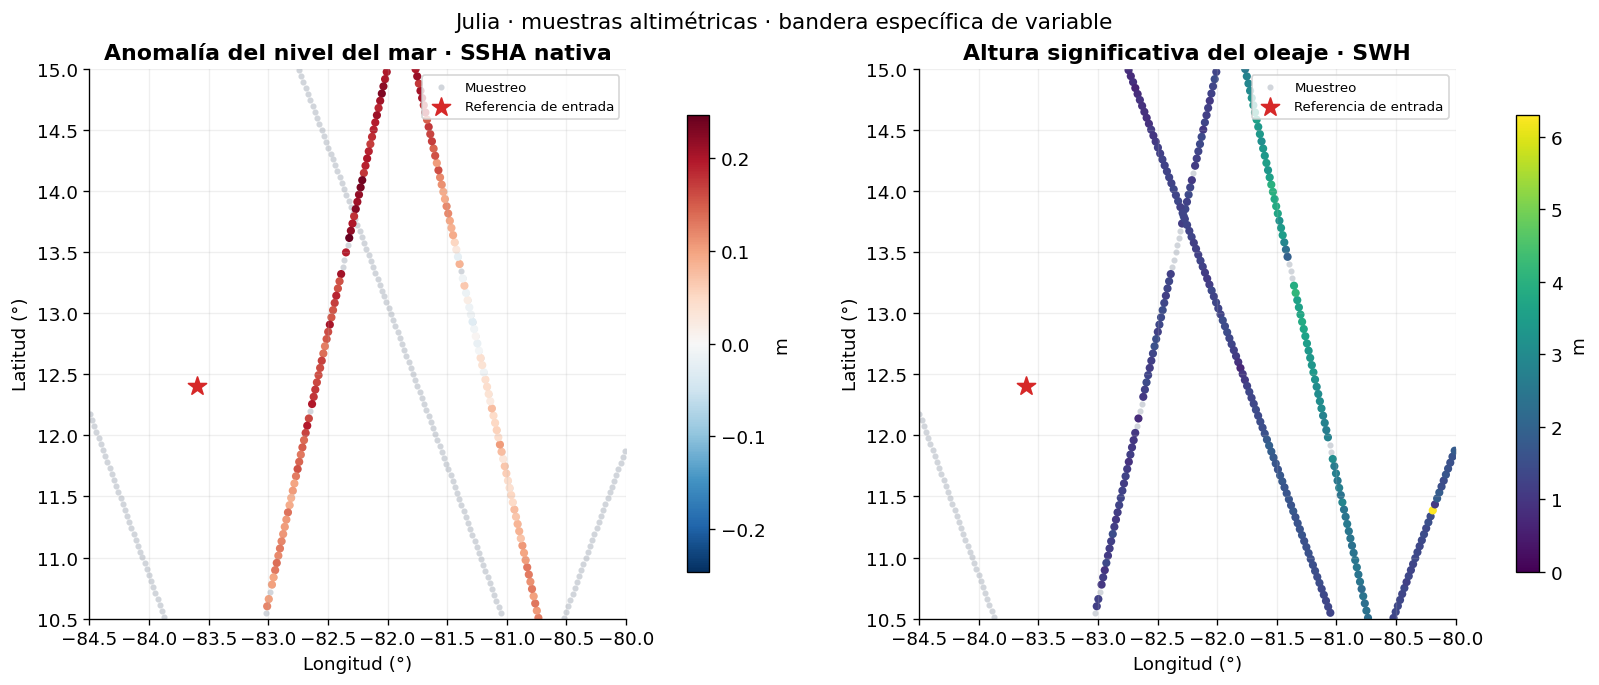

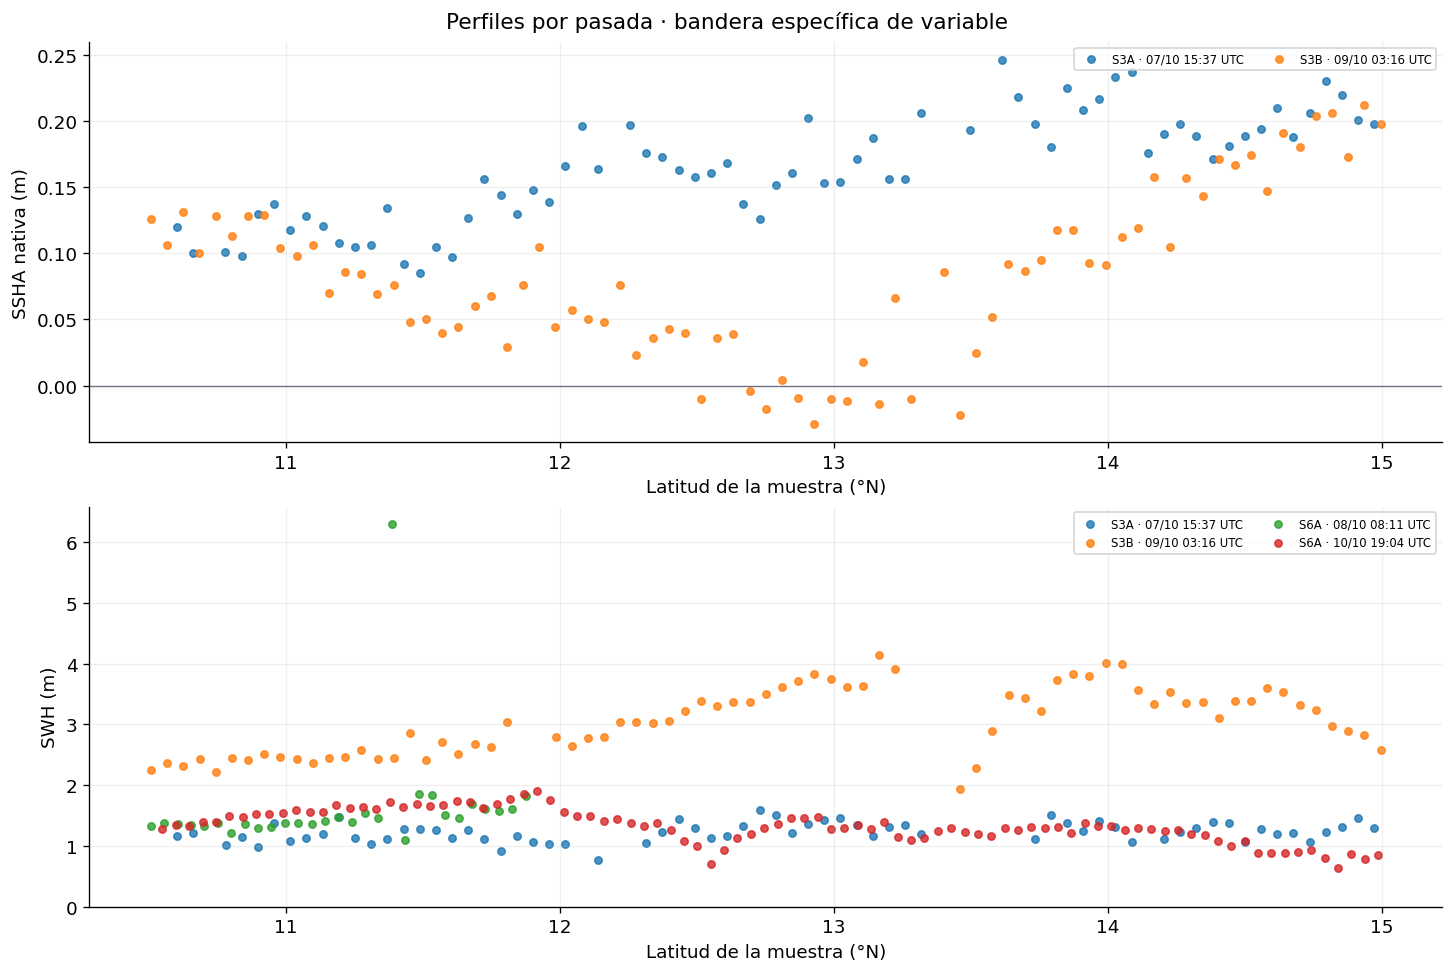

In [17]:
if not graficos.empty:
    fig, ejes = plt.subplots(1, 2, figsize=(13.5, 5.6), constrained_layout=True)
    for ax, variable, titulo, paleta in zip(ejes, ["ssha_m", "swh_m"],
        ["Anomalía del nivel del mar · SSHA nativa", "Altura significativa del oleaje · SWH"],
        ["RdBu_r", "viridis"]):
        ax.scatter(datos.longitud, datos.latitud, s=7, color="#d1d5db", label="Muestreo")
        sub = graficos.loc[np.isfinite(graficos[variable])]
        if len(sub):
            if variable == "ssha_m":
                limite = max(.05, float(sub[variable].abs().max()))
                vmin, vmax = -limite, limite
            else:
                vmin, vmax = 0, max(.1, float(sub[variable].max()))
            imagen = ax.scatter(sub.longitud, sub.latitud, c=sub[variable], cmap=paleta,
                                s=24, vmin=vmin, vmax=vmax, edgecolors="none")
            fig.colorbar(imagen, ax=ax, shrink=.83, label="m")
        else:
            ax.text(.5, .5, "Sin valores que cumplan el criterio", transform=ax.transAxes,
                    ha="center", bbox={"facecolor":"white", "alpha":.9})
        ax.scatter(*PUNTO_IMPACTO, marker="*", s=130, color="#d62828", label="Referencia de entrada")
        ax.set(xlim=(OESTE, ESTE), ylim=(SUR, NORTE), xlabel="Longitud (°)", ylabel="Latitud (°)", title=titulo)
        ax.set_aspect(1/np.cos(np.radians((SUR+NORTE)/2)))
        ax.grid(alpha=.2); ax.legend(loc="upper right", fontsize=8)
    fig.suptitle("Julia · muestras altimétricas · " + ROTULO_QC, fontsize=13)
    fig.savefig(SALIDA / "mapas_ssha_swh.png", bbox_inches="tight")
    plt.show()

    fig, ejes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
    for producto, g in graficos.groupby("producto", sort=False):
        etiqueta = f"{g.satelite.iloc[0]} · {g.tiempo_UTC.min():%d/%m %H:%M} UTC"
        for ax, variable in zip(ejes, ["ssha_m", "swh_m"]):
            sub = g.dropna(subset=[variable])
            if len(sub):
                ax.scatter(sub.latitud, sub[variable], s=19, alpha=.8, label=etiqueta)
    for ax, etiqueta in zip(ejes, ["SSHA nativa (m)", "SWH (m)"]):
        ax.set(xlabel="Latitud de la muestra (°N)", ylabel=etiqueta)
        ax.grid(alpha=.2)
        if ax.collections:
            ax.legend(fontsize=7, ncol=2, loc="best")
        else:
            ax.text(.5, .5, "Sin valores que cumplan el criterio", ha="center", transform=ax.transAxes)
    ejes[0].axhline(0, color="#6b7280", lw=.8)
    ejes[1].set_ylim(bottom=0)
    fig.suptitle("Perfiles por pasada · " + ROTULO_QC, fontsize=13)
    fig.savefig(SALIDA / "perfiles_por_pasada.png", bbox_inches="tight")
    plt.show()
else:
    print("No se generan gráficos sin observaciones locales.")

## 11 · Interpretar las correcciones y los límites del caso
**No sume ni reste correcciones sin revisar la ecuación de la versión concreta.** La SSHA distribuida
puede tener retiradas contribuciones de marea y respuesta atmosférica. El lector exporta las correcciones
reconocidas con el prefijo `correccion__`, sin modificarlas ni sumarlas automáticamente.

En Sentinel-6, DAC representa la respuesta a viento y presión; el algoritmo utiliza la corrección
barométrica inversa como alternativa cuando corresponde. En Sentinel-3 pueden aparecer
`inv_bar_cor_01` y `hf_fluct_cor_01`. No deben sumarse a una DAC que ya incluya ambas contribuciones.
Una reconstrucción posterior exige comprobar signos, banderas, correcciones realmente aplicadas,
superficie media de referencia y consistencia con mareógrafos o un modelo hidrodinámico.

**Preguntas para el grupo**
1. ¿Cuál es la muestra más cercana a Laguna de Perlas y cuántas horas la separan del impacto?
2. ¿Las tres misiones observaron el mismo sector y la misma fase del evento?
3. ¿Hay datos rechazados cerca de la costa? ¿Qué máscara o bandera los excluyó?
4. ¿Un máximo de SWH implica necesariamente un máximo de sobrelevación del mar?
5. ¿Qué evidencia falta para atribuir una SSHA a marejada y estimar el máximo costero?

La distancia al punto de entrada es una referencia geométrica. No es distancia a toda la costa,
ni distancia al centro móvil del ciclón. Este notebook no aplica intercalibración entre misiones,
no resta una climatología propia y no calcula un máximo de marejada.

In [ ]:
if not datos.empty:
    columnas = [c for c in datos if c.startswith("correccion__")]
    if columnas:
        display(datos[["satelite", "tiempo_UTC", "latitud", "longitud"]+columnas].head(15))
        print("Correcciones exportadas sin combinar:", ", ".join(columnas))
    else:
        print("El archivo elegido no contiene las correcciones reconocidas. Revisar el inventario y probar STD.")

## 12 · Exportar, repetir y resolver problemas
El ZIP contiene el inventario, las muestras, auditorías, figuras y mapa de **esta ejecución**.
No contiene claves ni tokens. Los NetCDF quedan en `Julia_Altimetria_resultados/netcdf` y se pueden incluir
activando la opción de la celda; así el ZIP puede crecer bastante.

| Situación | Acción |
|---|---|
| HTTP 401/403 | Revisar key/secret y licencia en Data Store. No usar usuario/contraseña. |
| Cero coincidencias | Verificar colección histórica, fechas UTC y orden oeste-sur-este-norte. |
| Error de búsqueda | No concluir que faltan datos; revisar conectividad y servicio. |
| Productos pero cero muestras locales | Seleccionar otras pasadas o ampliar región/fechas; el catálogo usa geometrías aproximadas. |
| Archivo RED/STD no identificado | Inspeccionar `list(objetos[(coleccion, producto)].entries)` y adaptar `elegir_entrada`. |
| SSHA vacía, SWH presente | Revisar bandera específica y correcciones; no reemplazar automáticamente por otra variable. |
| Muchas muestras excluidas | Leer `auditoria_lectura.json`; usar QC parcial solo para exploración, conservando el rótulo. |
| Colección retirada | Consultar catálogo oficial y reemplazar el ID por una colección L2 que cubra 2022. |
| Timeout/429/descarga interrumpida | Reejecutar; las descargas completas se reutilizan y los fragmentos no se aceptan. |

**Control de reproducción:** el inventario de cobertura corresponde solo a los productos seleccionados y
descargados correctamente, no a todas las observaciones posibles de Julia.

In [ ]:
INCLUIR_NETCDF_EN_ZIP = False
configuracion = {"inicio_UTC": INICIO_UTC, "fin_UTC": FIN_UTC, "impacto_UTC": IMPACTO_UTC,
    "bbox_oeste_sur_este_norte": BBOX, "punto_impacto_lon_lat": PUNTO_IMPACTO,
    "colecciones": COLECCIONES, "variante_solicitada": VARIANTE,
    "max_descargas": MAX_DESCARGAS, "indices_elegidos": list(seleccion.index),
    "solo_bandera_de_variable": SOLO_BANDERA_DE_VARIABLE,
    "eumdac_version": eumdac.__version__, "python_version": sys.version.split()[0],
    "ejecucion_UTC": datetime.now(timezone.utc).isoformat(),
    "interpretacion": "SSHA nativa corregida, no estimación directa de marejada"}
(SALIDA / "configuracion.json").write_text(json.dumps(configuracion, indent=2, ensure_ascii=False), encoding="utf-8")
salidas = [SALIDA / n for n in ["configuracion.json", "estado_busqueda.csv", "descargas.json", "auditoria_lectura.json"]]
if not inventario.empty: salidas.append(SALIDA / "inventario_catalogo.csv")
if archivos: salidas.append(SALIDA / "variables_ejemplo.csv")
if fallos_descarga: salidas.append(SALIDA / "fallos_descarga.csv")
if errores_lectura: salidas.append(SALIDA / "errores_lectura.csv")
if not datos.empty:
    salidas += [SALIDA / n for n in ["muestras_region.csv", "resumen_pasadas.csv", "mapa_pasadas.html",
                                    "mapas_ssha_swh.png", "perfiles_por_pasada.png"]]
if INCLUIR_NETCDF_EN_ZIP:
    for _, ruta in archivos:
        salidas.extend([ruta, ruta.with_suffix(".json")])
paquete = SALIDA / "Julia_Altimetria_resultados.zip"
with zipfile.ZipFile(paquete, "w", zipfile.ZIP_DEFLATED) as z:
    for ruta in salidas:
        if ruta.is_file(): z.write(ruta, arcname=str(ruta.relative_to(SALIDA)))
print("Paquete generado:", paquete.resolve())
try:
    from google.colab import files
    print("En Colab, ejecute: files.download(str(paquete))")
except ImportError:
    from IPython.display import FileLink
    display(FileLink(str(paquete)))

### Comandos CLI equivalentes (una línea por comando)
Los comandos siguientes solo muestran la búsqueda. La autenticación del cliente CLI es independiente
de la sesión Python; configurar con `eumdac set-credentials CONSUMER_KEY CONSUMER_SECRET`
puede dejar secretos en el historial de la terminal. En este notebook se recomienda la entrada oculta.

```powershell
eumdac search -c EO:EUM:DAT:1079 -s 2022-10-07T00:00:00 -e 2022-10-11T00:00:00 --bbox -84.5 10.5 -80.0 15.0
```
```powershell
eumdac search -c EO:EUM:DAT:1072 -s 2022-10-07T00:00:00 -e 2022-10-11T00:00:00 --bbox -84.5 10.5 -80.0 15.0
```

### Referencias y verificación
- [NHC: entrada de Julia, 09/10/2022 07:15 UTC](https://www.nhc.noaa.gov/archive/2022/al13/al132022.update.10090715.shtml).
- [EUMDAC: código y documentación oficiales](https://gitlab.eumetsat.int/eumetlab/data-services/eumdac).
- [SRAL L2 reprocesado BC006/G62, colección 1079](https://api.eumetsat.int/data/browse/collections/EO%3AEUM%3ADAT%3A1079?format=html).
- [Poseidon-4 L2 HR G01, colección 1072](https://api.eumetsat.int/data/browse/1.0.0/collections/EO%3AEUM%3ADAT%3A1072?format=html).
- [Poseidon-4 L2 LR G01, colección 1074](https://user.eumetsat.int/catalogue/EO%3AEUM%3ADAT%3A1074).
- [Sentinel-3: aviso de producto y banderas de calidad, v3E](https://user.eumetsat.int/s3/ope-eup-strapi-media/Copernicus_Sentinel_3_Product_Notice_STM_L1_and_L2_Marine_v3_E_4a9e31cf3f.pdf).
- [Sentinel-6: especificación del procesamiento L2, v5](https://user.eumetsat.int/s3/eup-strapi-media/Sentinel_6_Jason_CS_ALT_Level_2_Product_Generation_Specification_L2_ALT_PGS_V5_09f3679da5.pdf).
- [AVISO: corrección atmosférica dinámica](https://www.aviso.altimetry.fr/en/data/products/auxiliary-products/dynamic-atmospheric-correction/description-atmospheric-corrections.html).

**Verificación con datos reales — 19/11/2026:** autenticación, búsqueda y descarga con EUMDAC 3.1.1;
se descargaron y leyeron los **7 archivos STD** encontrados con la configuración predeterminada.
Cuatro corresponden a Sentinel-3A/B y tres a Sentinel-6A. El recorte real identificó **309 muestras
en 5 productos**; otros 2 productos no contienen muestras dentro de la región.

Con la máscara oceánica y las banderas disponibles, los gráficos predeterminados admiten
**146 valores de SSHA de Sentinel-3** y **257 valores de SWH entre las misiones**.
Los valores de SSHA de Sentinel-6 con solo bandera de rango se conservan en CSV, pero se excluyen
de los gráficos por defecto. Las muestras no son observaciones simultáneas ni una estimación del máximo de marejada.

La pasada local más próxima en tiempo fue **Sentinel-3B el 09/10 a las 03:17 UTC**, aproximadamente
**4 horas antes del impacto**. Su muestra más cercana al punto de entrada quedó a **258 km**.
Esta separación espacial impide tratar esa pasada como una medición directa del máximo costero en Laguna de Perlas.
Se ejecutaron también todas las celdas de análisis, mapas y exportación con los archivos reales descargados.

La validación también cubre lectura plana y con grupos, escalas, recortes, banderas, selección de entradas,
caché, integridad y exportación mediante pruebas separadas con datos sintéticos.
El notebook se entrega con las salidas de ejecución vacías para que cada participante genere sus resultados
con sus propias claves. Los recuentos anteriores documentan una consulta concreta, no un resultado garantizado
si cambian la configuración, las colecciones o el procesamiento del proveedor.

Cartografía incorporada: [Natural Earth, dominio público](https://www.naturalearthdata.com/about/terms-of-use/).
Visor incorporado: Leaflet 1.9.4 y jQuery 3.7.1; sus licencias se incluyen en el HTML.

Datos: EUMETSAT / Copernicus. Conservar identificadores de productos, versión y atribución al compartir resultados.